# Who wins? Predicting Pokémon battles with machine learning

**Created by [Juan Barahona](https://github.com/elmandalorian-thx)** ·
[Interactive guide](https://elmandalorian-thx.github.io/PokemonML/) ·
[Repository](https://github.com/elmandalorian-thx/PokemonML)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/elmandalorian-thx/PokemonML/blob/main/notebooks/pokemon_battle_ml.ipynb)

This notebook is the code companion to the interactive guide. It works through a complete supervised-learning project on a
small, fun dataset: given two Pokémon, predict which one wins the battle.

### 📖 The book

The project follows the workflow taught in:

> **Aurélien Géron, *Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow*, 3rd edition.**
> O'Reilly Media, 2022. ISBN 978-1-098-12597-4. Official code: https://github.com/ageron/handson-ml3

Comments and notes marked **📖** point to the chapter and section of the book that explains each idea in depth.
They are short summaries in our own words, so read the book for the full explanation, the math and many more examples.

### 🗂️ The data: credit to Kaggle and its authors

**[Pokemon – Weedle's Cave](https://www.kaggle.com/datasets/terminus7/pokemon-challenge)** (the “Pokemon Challenge”),
published on **Kaggle** by **T7 – Hackathon Challenge** (`terminus7`), license **CC0: Public Domain**.
All credit for the dataset and the challenge goes to its authors. According to their description, the Pokémon stats
come from the games, while the battle results were produced by a custom simulation algorithm.
A copy of the three CSV files is in this repository under [`data/raw/`](https://github.com/elmandalorian-thx/PokemonML/tree/main/data/raw).

### Roadmap

The steps mirror the project checklist from Chapter 2 of the book (“End-to-End Machine Learning Project”).

| # | Step | 📖 Where it is in the book |
|---|------|------------------------|
| 1 | Frame the problem | Ch. 1 *Types of Machine Learning Systems*; Ch. 2 *Frame the Problem*, *Select a Performance Measure* |
| 2 | Get the data and take a quick look | Ch. 2 *Get the Data*, *Take a Quick Look at the Data Structure* |
| 3 | Clean the data | Ch. 1 *Poor-Quality Data*; Ch. 2 *Clean the Data* |
| 4 | Create a test set (before exploring!) | Ch. 2 *Create a Test Set* |
| 5 | Explore and find correlations | Ch. 2 *Explore and Visualize the Data to Gain Insights*, *Look for Correlations* |
| 6 | Engineer features | Ch. 1 *Irrelevant Features*; Ch. 2 *Experiment with Attribute Combinations* |
| 7 | Baselines | Ch. 3 *Measuring Accuracy Using Cross-Validation* |
| 8 | Train and compare models with cross-validation | Ch. 2 *Select and Train a Model*, *Better Evaluation Using Cross-Validation*; Ch. 4 *Logistic Regression*; Ch. 6 *Decision Trees*; Ch. 7 *Gradient Boosting* |
| 9 | Overfitting and learning curves | Ch. 1 *Overfitting the Training Data*; Ch. 4 *Learning Curves*; Ch. 6 *Regularization Hyperparameters* |
| 10 | Evaluate on the test set | Ch. 2 *Evaluate Your System on the Test Set*; Ch. 3 *Confusion Matrices*, *The ROC Curve* |
| 11 | Analyse the model and its errors | Ch. 2 *Analyzing the Best Models and Their Errors*; Ch. 7 *Feature Importance* |
| 12 | Present: battle predictions + Kaggle submission | Ch. 2 checklist: present and launch |

## 0 · Setup

The book's preface assumes you know Python and its scientific stack (NumPy, pandas, Matplotlib); Part I is built on
Scikit-Learn, and so is this notebook. If you opened it in Colab, everything below is already installed.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn

from sklearn.dummy import DummyClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, RocCurveDisplay, accuracy_score,
                             confusion_matrix, log_loss, roc_auc_score)
from sklearn.model_selection import (GroupShuffleSplit, cross_val_score, learning_curve,
                                     train_test_split)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree

# 📖 Ch. 2 "Create a Test Set": fix the random seed so every run gives the same split
# and the same results. Reproducibility makes experiments comparable.
SEED = 42

# Chart colours (the same palette the interactive guide uses)
BLUE, ORANGE, AQUA, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#c3c2b7"
plt.rcParams.update({"figure.figsize": (8, 4), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.8})

print("scikit-learn", sklearn.__version__, "| pandas", pd.__version__)

scikit-learn 1.9.1 | pandas 3.1.0


## 1 · Frame the problem

> 📖 **Ch. 1, “Types of Machine Learning Systems”** · **Ch. 2, “Frame the Problem” and “Select a Performance Measure”**

Before writing code, the book asks you to pin down the objective, the type of learning and how success will be measured.

* **Task:** *supervised learning*. Every past battle is a labelled example: two inputs (the fighters) and a known answer (the winner).
* **Type:** *binary classification* (📖 Ch. 3, “Classification”). The target is `1` if the **first** Pokémon wins and `0` if the second does.
  A *probability* of winning is more useful than a bare label, because it says how confident the model is.
* **Performance measure:** *accuracy* on battles the model has never seen. Classes are almost balanced (about 47% / 53%), so accuracy is
  a fair metric here. Chapter 3 shows why it can badly mislead on skewed classes.
* **What we already know:** the Kaggle description says battles were simulated. A simulator follows rules, so a model may be
  able to rediscover them.

## 2 · Get the data and take a quick look

> 📖 **Ch. 2, “Get the Data” → “Take a Quick Look at the Data Structure”**

The three CSV files ship with this repository in `data/raw/`. When the notebook runs somewhere without the repo (for example Colab),
it reads the same files from GitHub instead.

In [2]:
# Read locally if the repo is checked out, otherwise straight from GitHub (works in Colab).
LOCAL = Path("../data/raw")
REMOTE = "https://raw.githubusercontent.com/elmandalorian-thx/PokemonML/main/data/raw/"

def load(name: str) -> pd.DataFrame:
    path = LOCAL / name
    return pd.read_csv(path if path.exists() else REMOTE + name)

pokemon = load("pokemon.csv").set_index("#")   # one row per Pokémon: the features
combats = load("combats.csv")                  # who fought whom and who won: the labels
tests   = load("tests.csv")                    # matchups without a winner: the Kaggle exam

print(pokemon.shape, combats.shape, tests.shape)
pokemon.head()

(800, 11) (50000, 3) (10000, 2)


,Name,Type 1,Type 2,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed,Generation,Legendary
#,,,,,,,,,,,
1,Bulbasaur,Grass,Poison,45,49,49,65,65,45,1,False
2,Ivysaur,Grass,Poison,60,62,63,80,80,60,1,False
3,Venusaur,Grass,Poison,80,82,83,100,100,80,1,False
4,Mega Venusaur,Grass,Poison,80,100,123,122,120,80,1,False
5,Charmander,Fire,NaN,39,52,43,60,50,65,1,False


In [3]:
# 📖 Ch. 2 uses .info() and .describe() first: check the column types, count the missing values
# and look at the range of every numeric column before doing anything else.
pokemon.info()

<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 1 to 800
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Name        799 non-null    str  
 1   Type 1      800 non-null    str  
 2   Type 2      414 non-null    str  
 3   HP          800 non-null    int64
 4   Attack      800 non-null    int64
 5   Defense     800 non-null    int64
 6   Sp. Atk     800 non-null    int64
 7   Sp. Def     800 non-null    int64
 8   Speed       800 non-null    int64
 9   Generation  800 non-null    int64
 10  Legendary   800 non-null    bool 
dtypes: bool(1), int64(7), str(3)
memory usage: 63.4 KB


In [4]:
pokemon.describe().round(1)

,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed,Generation
count,800.0,800.0,800.0,800.0,800.0,800.0,800.0
mean,69.3,79.0,73.8,72.8,71.9,68.3,3.3
std,25.5,32.5,31.2,32.7,27.8,29.1,1.7
min,1.0,5.0,5.0,10.0,20.0,5.0,1.0
25%,50.0,55.0,50.0,49.8,50.0,45.0,2.0
50%,65.0,75.0,70.0,65.0,70.0,65.0,3.0
75%,80.0,100.0,90.0,95.0,90.0,90.0,5.0
max,255.0,190.0,230.0,194.0,230.0,180.0,6.0


In [5]:
# The labels: three ids per row. The model's job is to learn what makes the winner's row
# in `pokemon` different from the loser's.
combats.head()

,First_pokemon,Second_pokemon,Winner
0,266,298,298
1,702,701,701
2,191,668,668
3,237,683,683
4,151,231,151


## 3 · Clean the data

> 📖 **Ch. 1, “Poor-Quality Data”** · **Ch. 2, “Clean the Data”**

The book lists three ways to handle missing values: drop the rows, drop the column, or fill the gaps in (imputation). The
right choice depends on **why** a value is missing, so we look before we fix anything.

In [6]:
pokemon.isna().sum()[lambda s: s > 0]

Name        1
Type 2    386
dtype: int64

In [7]:
# 1) One Pokémon has no name. Its stats are Fighting-type, Gen 1, 65/105/60/60/70/95,
#    which match Primeape exactly, so we repair the row instead of dropping it.
display(pokemon.loc[[63]])
pokemon.loc[63, "Name"] = "Primeape"

# 2) 386 "missing" Type 2 values are not missing data: those Pokémon have only one type.
#    Imputing them (e.g. with the most frequent type) would invent information.
#    Encode the real meaning instead: an empty string for "no second type".
pokemon["Type 2"] = pokemon["Type 2"].fillna("")

# 3) A derived column we'll use a lot: the sum of the six base stats.
STATS = ["HP", "Attack", "Defense", "Sp. Atk", "Sp. Def", "Speed"]
pokemon["Total"] = pokemon[STATS].sum(axis=1)

# 4) Note: "#" is a row id, not the Pokédex number (Mega forms have their own rows).
pokemon.loc[[6, 7, 8]][["Name", "Total"]]

,Name,Type 1,Type 2,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed,Generation,Legendary
#,,,,,,,,,,,
63,NaN,Fighting,NaN,65,105,60,60,70,95,1,False


,Name,Total
#,,
6,Charmeleon,405
7,Charizard,534
8,Mega Charizard X,634


## 4 · Create a test set before exploring

> 📖 **Ch. 2, “Create a Test Set”**

The book's advice is to set the test set aside **before** looking at the data closely. If you explore all of it, your brain
picks up patterns from the test set too, and you end up choosing models that fit it. The book calls this *data snooping bias*.

We hold out 20% of the battles, **stratified** on the label so both parts have the same win/loss balance (stratified sampling
is also covered in “Create a Test Set”). From here on, all exploration and model selection uses the training battles only.

In [8]:
y_all = (combats.Winner == combats.First_pokemon).astype(int).values   # 1 = first Pokémon won

idx_train, idx_test = train_test_split(
    np.arange(len(combats)), test_size=0.2, random_state=SEED,
    stratify=y_all,          # keep the ~47/53 class balance identical in both parts
)
train_battles, test_battles = combats.iloc[idx_train], combats.iloc[idx_test]
y_train, y_test = y_all[idx_train], y_all[idx_test]
print(f"{len(train_battles):,} training battles · {len(test_battles):,} test battles (locked away)")
print(f"first Pokémon wins: train {y_train.mean():.3f} · test {y_test.mean():.3f}")

40,000 training battles · 10,000 test battles (locked away)
first Pokémon wins: train 0.472 · test 0.472


## 5 · Explore and find correlations

> 📖 **Ch. 2, “Explore and Visualize the Data to Gain Insights” → “Look for Correlations”**

The book explores the data with plots and a correlation matrix to form hypotheses. Here each Pokémon gets a *win rate* (wins ÷ battles,
from the **training** battles only), and we ask which stat moves it.

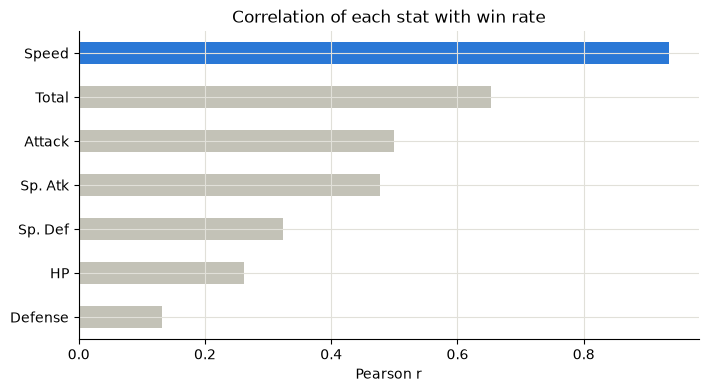

Defense    0.132
HP         0.262
Sp. Def    0.324
Sp. Atk    0.477
Attack     0.499
Total      0.653
Speed      0.935
Name: win_rate, dtype: float64

In [9]:
games = pd.concat([train_battles.First_pokemon, train_battles.Second_pokemon]).value_counts()
wins = train_battles.Winner.value_counts()
pokemon["win_rate"] = (wins / games).reindex(pokemon.index)   # NaN for Pokémon with no training battles

# 📖 "Look for Correlations": the standard correlation coefficient (Pearson's r) of every stat with the win rate.
# r close to 1 = strong positive linear relationship. It only captures *linear* relationships.
corr = pokemon[STATS + ["Total", "win_rate"]].corr()["win_rate"].drop("win_rate").sort_values()
ax = corr.plot.barh(color=[BLUE if s == "Speed" else GRAY for s in corr.index])
ax.set(title="Correlation of each stat with win rate", xlabel="Pearson r")
plt.show()
corr.round(3)

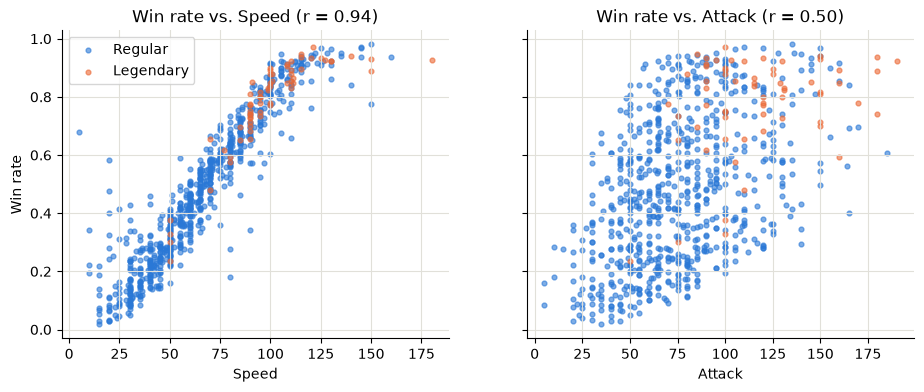

In [10]:
# The book's scatter plots reveal structure that a single number can't. Speed vs. win rate:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, stat in zip(axes, ["Speed", "Attack"]):
    for legendary, color, label in [(False, BLUE, "Regular"), (True, ORANGE, "Legendary")]:
        d = pokemon[pokemon.Legendary == legendary]
        ax.scatter(d[stat], d.win_rate, s=12, alpha=0.6, color=color, label=label)
    ax.set(xlabel=stat, title=f"Win rate vs. {stat} (r = {corr[stat]:.2f})")
axes[0].set_ylabel("Win rate"); axes[0].legend()
plt.show()

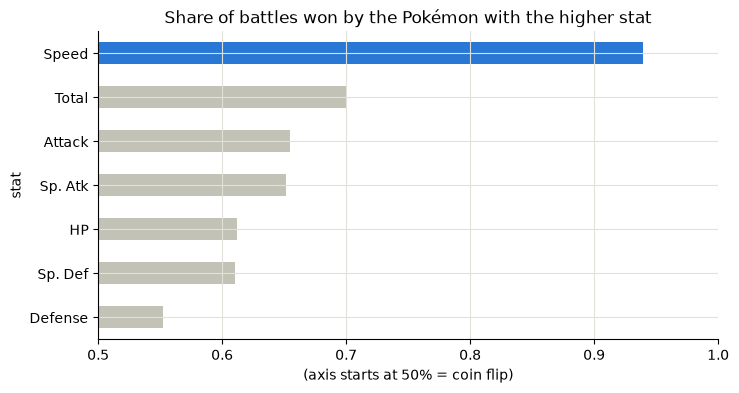

,higher_stat_wins,ties
stat,,
Defense,0.552,0.031
Sp. Def,0.610,0.035
HP,0.612,0.039
Sp. Atk,0.651,0.029
Attack,0.655,0.025
Total,0.700,0.012
Speed,0.939,0.026


In [11]:
# A direct test of the hypothesis: in how many battles does the Pokémon with the higher stat win?
A = pokemon.loc[train_battles.First_pokemon, STATS + ["Total"]].values
B = pokemon.loc[train_battles.Second_pokemon, STATS + ["Total"]].values
rows = []
for i, stat in enumerate(STATS + ["Total"]):
    diff = A[:, i] - B[:, i]
    decided = diff != 0                                   # ignore ties for this rule
    rows.append({"stat": stat, "higher_stat_wins": ((diff > 0) == y_train)[decided].mean(),
                 "ties": (~decided).mean()})
higher = pd.DataFrame(rows).set_index("stat").sort_values("higher_stat_wins")
ax = higher.higher_stat_wins.plot.barh(color=[BLUE if s == "Speed" else GRAY for s in higher.index], xlim=(0.5, 1))
ax.set(title="Share of battles won by the Pokémon with the higher stat", xlabel="(axis starts at 50% = coin flip)")
plt.show()
higher.round(3)

**The headline finding:** the faster Pokémon wins about **94%** of battles. “Total stats”, the obvious power level, manages only about 70%.

Now look at the edge cases. When Speed is **tied**, who wins?

In [12]:
speed_diff = A[:, STATS.index("Speed")] - B[:, STATS.index("Speed")]
tie = speed_diff == 0
print(f"speed ties: {tie.sum():,} battles · first Pokémon wins {y_train[tie].mean():.1%} of them")
print(f"legendary win rate {pokemon[pokemon.Legendary].win_rate.mean():.1%} vs regular {pokemon[~pokemon.Legendary].win_rate.mean():.1%}")

speed ties: 1,035 battles · first Pokémon wins 0.0% of them
legendary win rate 78.1% vs regular 47.7%


Two notes for later:

1. **Speed ties always go to the second Pokémon.** Kaggle's description says the first Pokémon attacks first; the data says
   Speed decides who strikes first, and the *second* Pokémon wins a tie. **Always check the documentation against the data.**
2. **Legendaries win far more often**, but they are also much faster. That could be *confounding*, and Section 11 will
   separate the two effects.

## 6 · Engineer the features

> 📖 **Ch. 1, “Irrelevant Features”** (feature engineering: selecting, extracting and creating features) ·
> **Ch. 2, “Experiment with Attribute Combinations”**

A model can't read “Pikachu vs Gyarados”; it needs one row of numbers per battle. A battle is about the *relationship* between two
Pokémon, so every feature compares A against B, and positive means “A has the edge”. Like the book's *rooms per household*,
the combinations carry more signal than the raw columns:

* six **stat differences**, the **total** difference and a **legendary** difference;
* **type advantage**: game rules the CSV doesn't contain (Water beats Fire, Ground is immune to Electric, …);
* **physical / special edge**: damage scales with *Attack ÷ Defense*, so we compare **ratios** on a log scale, not differences.

In [13]:
# Gen-6 type chart: attacking type -> {defending type: multiplier}. Anything not listed is 1x.
TYPE_CHART = {
    "Normal": {"Rock": .5, "Steel": .5, "Ghost": 0},
    "Fire": {"Grass": 2, "Ice": 2, "Bug": 2, "Steel": 2, "Fire": .5, "Water": .5, "Rock": .5, "Dragon": .5},
    "Water": {"Fire": 2, "Ground": 2, "Rock": 2, "Water": .5, "Grass": .5, "Dragon": .5},
    "Electric": {"Water": 2, "Flying": 2, "Electric": .5, "Grass": .5, "Dragon": .5, "Ground": 0},
    "Grass": {"Water": 2, "Ground": 2, "Rock": 2, "Fire": .5, "Grass": .5, "Poison": .5, "Flying": .5, "Bug": .5, "Dragon": .5, "Steel": .5},
    "Ice": {"Grass": 2, "Ground": 2, "Flying": 2, "Dragon": 2, "Fire": .5, "Water": .5, "Ice": .5, "Steel": .5},
    "Fighting": {"Normal": 2, "Ice": 2, "Rock": 2, "Dark": 2, "Steel": 2, "Poison": .5, "Flying": .5, "Psychic": .5, "Bug": .5, "Fairy": .5, "Ghost": 0},
    "Poison": {"Grass": 2, "Fairy": 2, "Poison": .5, "Ground": .5, "Rock": .5, "Ghost": .5, "Steel": 0},
    "Ground": {"Fire": 2, "Electric": 2, "Poison": 2, "Rock": 2, "Steel": 2, "Grass": .5, "Bug": .5, "Flying": 0},
    "Flying": {"Grass": 2, "Fighting": 2, "Bug": 2, "Electric": .5, "Rock": .5, "Steel": .5},
    "Psychic": {"Fighting": 2, "Poison": 2, "Psychic": .5, "Steel": .5, "Dark": 0},
    "Bug": {"Grass": 2, "Psychic": 2, "Dark": 2, "Fire": .5, "Fighting": .5, "Poison": .5, "Flying": .5, "Ghost": .5, "Steel": .5, "Fairy": .5},
    "Rock": {"Fire": 2, "Ice": 2, "Flying": 2, "Bug": 2, "Fighting": .5, "Ground": .5, "Steel": .5},
    "Ghost": {"Psychic": 2, "Ghost": 2, "Dark": .5, "Normal": 0},
    "Dragon": {"Dragon": 2, "Steel": .5, "Fairy": 0},
    "Dark": {"Psychic": 2, "Ghost": 2, "Fighting": .5, "Dark": .5, "Fairy": .5},
    "Steel": {"Ice": 2, "Rock": 2, "Fairy": 2, "Fire": .5, "Water": .5, "Electric": .5, "Steel": .5},
    "Fairy": {"Fighting": 2, "Dragon": 2, "Dark": 2, "Fire": .5, "Poison": .5, "Steel": .5},
}

def best_hit(attacker_types, defender_types):
    """Best multiplier any of the attacker's types gets against the defender's type combination."""
    best = 0.0
    for atk in filter(None, attacker_types):
        m = 1.0
        for d in filter(None, defender_types):
            m *= TYPE_CHART[atk].get(d, 1.0)
        best = max(best, m)
    return best

best_hit(("Electric", ""), ("Water", "Flying"))   # Pikachu vs Gyarados: 4x

4.0

In [14]:
FEATURES = ["d_hp", "d_atk", "d_def", "d_spa", "d_spd", "d_spe", "d_total", "d_legendary",
            "type_adv", "atk_edge", "spa_edge"]

def pair_features(a_ids, b_ids) -> pd.DataFrame:
    """One row per battle. Every feature compares A with B: swap them and its sign flips."""
    A, B = pokemon.loc[a_ids], pokemon.loc[b_ids]
    f = pd.DataFrame(index=range(len(A)))
    for stat, key in zip(STATS, ["hp", "atk", "def", "spa", "spd", "spe"]):
        f[f"d_{key}"] = A[stat].values - B[stat].values
    f["d_total"] = A.Total.values - B.Total.values
    f["d_legendary"] = A.Legendary.astype(int).values - B.Legendary.astype(int).values

    types_a = list(zip(A["Type 1"], A["Type 2"]))
    types_b = list(zip(B["Type 1"], B["Type 2"]))
    off_a = np.array([best_hit(ta, tb) for ta, tb in zip(types_a, types_b)])
    off_b = np.array([best_hit(tb, ta) for ta, tb in zip(types_a, types_b)])
    # log2 so that 2x vs 1/2x = +2 and even = 0; clip so an immunity (0x) doesn't become -infinity
    f["type_adv"] = np.log2(np.maximum(off_a, .25)) - np.log2(np.maximum(off_b, .25))

    # Ratio features: log(A.Atk / B.Def) - log(B.Atk / A.Def)
    ln = lambda s: np.log(s.values.astype(float))
    f["atk_edge"] = (ln(A["Attack"]) - ln(B["Defense"])) - (ln(B["Attack"]) - ln(A["Defense"]))
    f["spa_edge"] = (ln(A["Sp. Atk"]) - ln(B["Sp. Def"])) - (ln(B["Sp. Atk"]) - ln(A["Sp. Def"]))
    return f[FEATURES]

X_all = pair_features(combats.First_pokemon.values, combats.Second_pokemon.values)
X_train, X_test = X_all.iloc[idx_train].reset_index(drop=True), X_all.iloc[idx_test].reset_index(drop=True)
X_train.head()

,d_hp,d_atk,d_def,d_spa,d_spd,d_spe,d_total,d_legendary,type_adv,atk_edge,spa_edge
0,-28,-18,27,-21,16,-10,-34,0,-2.0,0.218562,-0.094311
1,5,-10,-40,28,10,-10,-17,0,1.0,-0.803043,0.839101
2,-20,0,-30,-10,5,-25,-80,0,3.0,-0.510826,-0.030772
3,44,42,-3,-30,-14,41,80,1,-2.0,0.419787,-0.458830
4,200,-59,-45,-10,55,9,150,0,-1.0,-4.852030,0.490623


## 7 · Baselines: what does “no intelligence” score?

> 📖 **Ch. 3, “Performance Measures” → “Measuring Accuracy Using Cross-Validation”**

In Chapter 3 the book shows a `DummyClassifier` reaching about 90% accuracy on MNIST by always answering “not a 5”, a
warning that a high accuracy number can mean nothing. Always compute what a trivial predictor scores before celebrating a model.

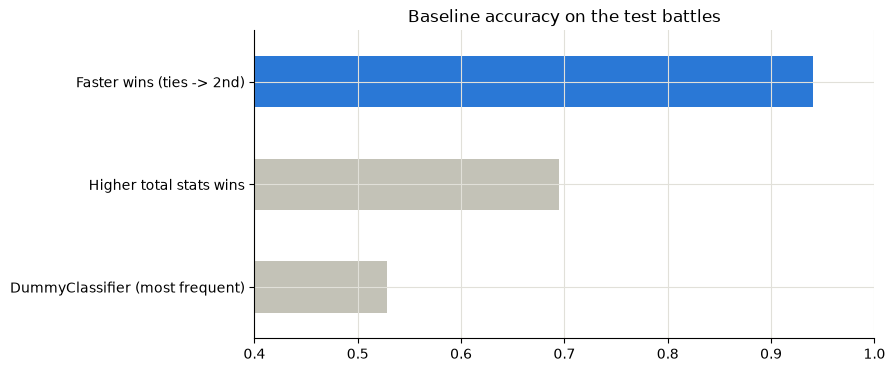

DummyClassifier (most frequent)    0.5280
Higher total stats wins            0.6950
Faster wins (ties -> 2nd)          0.9404
dtype: float64

In [15]:
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)    # always predicts the majority class

def rule(score):
    """Turn a rule's score into predictions: >0 -> A wins, <0 -> B wins."""
    return (np.asarray(score) > 0).astype(int)

baselines = pd.Series({
    "DummyClassifier (most frequent)": dummy.score(X_test, y_test),
    "Higher total stats wins":         accuracy_score(y_test, rule(X_test.d_total)),
    "Faster wins (ties -> 2nd)":       accuracy_score(y_test, rule(X_test.d_spe)),
}).sort_values()
ax = baselines.plot.barh(color=[GRAY, GRAY, BLUE], xlim=(0.4, 1), title="Baseline accuracy on the test battles")
plt.show()
baselines.round(4)

A one-line if-statement scores about **94%**. That's the bar every model must clear. Without it, an 88% model would sound impressive.

## 8 · Train and compare models with cross-validation

> 📖 **Ch. 2, “Select and Train a Model” → “Better Evaluation Using Cross-Validation”** ·
> **Ch. 4, “Logistic Regression”** · **Ch. 6, “Decision Trees”** · **Ch. 7, “Gradient Boosting”**

The book compares candidate models with **k-fold cross-validation** on the training set, so the test set stays untouched until the very end.
Three classic algorithms:

* **Logistic regression** (Ch. 4): a weighted sum of the features squashed into a probability. Linear models are sensitive to
  feature scale, so it gets a `StandardScaler` inside a **pipeline** (📖 Ch. 2 *Feature Scaling and Transformation*, *Transformation Pipelines*).
* **Decision tree** (Ch. 6): a series of yes/no questions. `max_depth=3` keeps it small enough to read.
* **Gradient boosting** (Ch. 7): many small trees trained one after another, each fitting the errors the previous ones left.

In [16]:
models = {
    # 📖 Ch. 2 "Transformation Pipelines": the scaler is fitted inside each CV fold, never on validation data
    "Logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    # 📖 Ch. 6 "Regularization Hyperparameters": max_depth limits how much the tree can memorise
    "Decision tree (depth 3)": DecisionTreeClassifier(max_depth=3, random_state=SEED),
    # 📖 Ch. 7 "Gradient Boosting": learning_rate shrinks each tree's contribution, and subsample<1
    # trains each tree on a random 80% of the rows (stochastic gradient boosting)
    "Gradient boosting": GradientBoostingClassifier(n_estimators=200, max_depth=4, learning_rate=0.1,
                                                    subsample=0.8, random_state=SEED),
}

cv_results = {}
for name, model in models.items():
    scores = cross_val_score(model, X_train, y_train, cv=3, scoring="accuracy")   # 3 folds keeps it quick
    cv_results[name] = scores
    print(f"{name:25s} CV accuracy {scores.mean():.4f} ± {scores.std():.4f}")

Logistic regression       CV accuracy 0.8847 ± 0.0025
Decision tree (depth 3)   CV accuracy 0.9434 ± 0.0025


Gradient boosting         CV accuracy 0.9498 ± 0.0016


Gradient boosting wins, the tree is close behind, and **logistic regression is below the 94% baseline**. Why?

A linear model assumes a smooth slope: 10 more Speed always adds the same amount to the log-odds. But the battle rule is a **step**:
being faster by 1 point is as good as being faster by 50. A straight line can't draw a step. The fix isn't a fancier model, it's
a better feature. We add an “is A faster?” indicator:

In [17]:
def with_faster(X):
    return X.assign(faster=(X.d_spe > 0).astype(int))   # a step function, handed to the model ready-made

lr_step = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
print("logistic regression + 'is faster' feature, CV accuracy:",
      cross_val_score(lr_step, with_faster(X_train), y_train, cv=3).mean().round(4))

logistic regression + 'is faster' feature, CV accuracy: 0.9451


### An experiment that fails: data augmentation

> 📖 **Ch. 3, exercises:** the book introduces *data augmentation* (training-set expansion) by adding shifted copies of MNIST images.
> Shifting an image doesn't change which digit it shows, so the label stays valid.

A tempting idea is to double the battles by adding each one again with A and B swapped (features negated, label flipped).
That assumes order doesn't matter. Section 5 showed it does: speed ties always go to the second Pokémon. Let's measure it:

In [18]:
X_aug = pd.concat([X_train, -X_train], ignore_index=True)          # swapped copies: every feature flips sign...
y_aug = np.concatenate([y_train, 1 - y_train])                      # ...and the label flips

gbm_plain = GradientBoostingClassifier(n_estimators=200, max_depth=4, subsample=0.8, random_state=SEED)
gbm_aug = GradientBoostingClassifier(n_estimators=200, max_depth=4, subsample=0.8, random_state=SEED)
print("without augmentation:", cross_val_score(gbm_plain, X_train, y_train, cv=3).mean().round(4))
gbm_aug.fit(X_aug, y_aug)
# Validate on a held-out slice of the *original* orientation (a quick, fair check of the same model family)
Xa_tr, Xa_val, ya_tr, ya_val = train_test_split(X_train, y_train, test_size=0.25, random_state=SEED, stratify=y_train)
gbm_aug.fit(pd.concat([Xa_tr, -Xa_tr]), np.concatenate([ya_tr, 1 - ya_tr]))
print("with augmentation   :", round(gbm_aug.score(Xa_val, ya_val), 4))

without augmentation: 0.9498


with augmentation   : 0.9373


Augmentation **hurts**, because it told the model the opposite of a real rule. Only augment with transformations you *know* keep the label valid, and measure the effect.

## 9 · Overfitting and learning curves

> 📖 **Ch. 1, “Overfitting the Training Data” / “Underfitting the Training Data”** ·
> **Ch. 6, “Regularization Hyperparameters”** · **Ch. 4, “Learning Curves”** (and the bias/variance trade-off sidebar)

Let a decision tree grow deeper: training accuracy keeps rising, but accuracy on unseen battles peaks and then falls. The extra
depth memorises noise. Restricting `max_depth` is *regularization*.

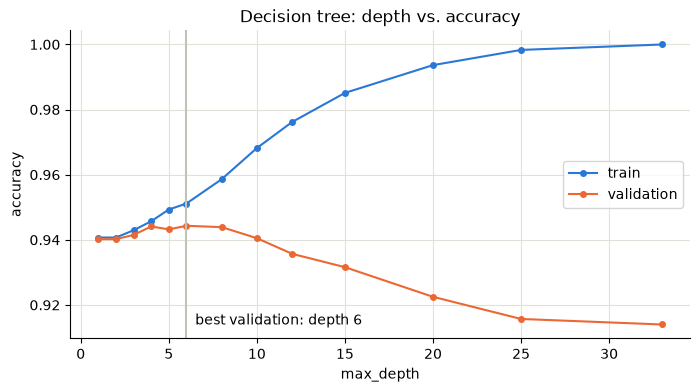

depth,1,2,3,4,5,6,8,10,12,15,20,25,33
train,0.9407,0.9407,0.9429,0.9457,0.9493,0.9511,0.9586,0.9682,0.9762,0.9851,0.9936,0.9983,1.000
validation,0.9402,0.9402,0.9415,0.9441,0.9432,0.9443,0.9439,0.9405,0.9357,0.9316,0.9225,0.9157,0.914


In [19]:
# Validation split carved out of the training set: the test set stays untouched (📖 Ch. 1 "Testing and Validating")
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.25, random_state=SEED, stratify=y_train)

depths = [1, 2, 3, 4, 5, 6, 8, 10, 12, 15, 20, 25, None]
curve = []
for d in depths:
    tree = DecisionTreeClassifier(max_depth=d, random_state=SEED).fit(X_tr, y_tr)
    curve.append((d or tree.get_depth(), tree.score(X_tr, y_tr), tree.score(X_val, y_val)))
curve = pd.DataFrame(curve, columns=["depth", "train", "validation"]).set_index("depth")

ax = curve.plot(color=[BLUE, ORANGE], marker="o", ms=4, title="Decision tree: depth vs. accuracy")
best = curve.validation.idxmax()
ax.axvline(best, color=GRAY); ax.text(best + 0.5, curve.values.min(), f"best validation: depth {best}")
ax.set(xlabel="max_depth", ylabel="accuracy"); plt.show()
curve.round(4).T

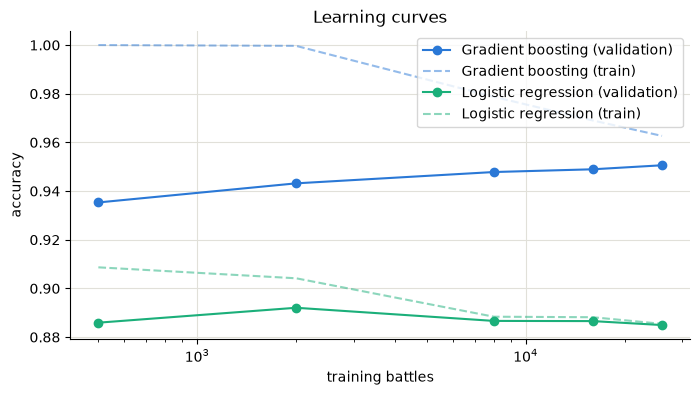

In [20]:
# 📖 Ch. 4 "Learning Curves": score the model on growing slices of the training data (with cross-validation).
# A model that keeps improving with data is variance-limited; one that stays flat is bias-limited
# (its assumptions are wrong, so more data won't help).
sizes = [500, 2000, 8000, 16000, 26000]   # each 3-fold training split holds ~26.6K battles
fig, ax = plt.subplots()
for name, model, color in [("Gradient boosting", models["Gradient boosting"], BLUE),
                           ("Logistic regression", models["Logistic regression"], AQUA)]:
    n, train_sc, val_sc = learning_curve(model, X_train, y_train, train_sizes=sizes, cv=3, scoring="accuracy")
    ax.plot(n, val_sc.mean(axis=1), "o-", color=color, label=f"{name} (validation)")
    ax.plot(n, train_sc.mean(axis=1), "--", color=color, alpha=0.5, label=f"{name} (train)")
ax.set(xscale="log", xlabel="training battles", ylabel="accuracy", title="Learning curves"); ax.legend()
plt.show()

Logistic regression is flat at about 88%: its problem is its shape (**bias**), not a lack of data. Boosting improves with more data but is already leveling off.

## 10 · Evaluate on the test set, once

> 📖 **Ch. 2, “Evaluate Your System on the Test Set”** · **Ch. 3, “Confusion Matrices”, “The ROC Curve”**

Model selection is done, so we train the chosen models on the full training set and score them **once** on the locked test set.
If we went back and tweaked things after seeing these numbers, the test set would stop being an honest estimate.

In [21]:
for model in models.values():
    model.fit(X_train, y_train)

report = pd.DataFrame({
    name: {"train acc": accuracy_score(y_train, m.predict(X_train)),
           "test acc": accuracy_score(y_test, m.predict(X_test)),
           "log loss": log_loss(y_test, m.predict_proba(X_test)[:, 1]),
           "ROC AUC": roc_auc_score(y_test, m.predict_proba(X_test)[:, 1])}
    for name, m in models.items()}).T
report.loc["Baseline: faster wins"] = [np.nan, baselines["Faster wins (ties -> 2nd)"], np.nan, np.nan]
report.round(4)

,train acc,test acc,log loss,ROC AUC
Logistic regression,0.8852,0.8816,0.3638,0.9277
Decision tree (depth 3),0.9426,0.9415,0.1909,0.9644
Gradient boosting,0.9598,0.9507,0.1559,0.9801
Baseline: faster wins,NaN,0.9404,NaN,NaN


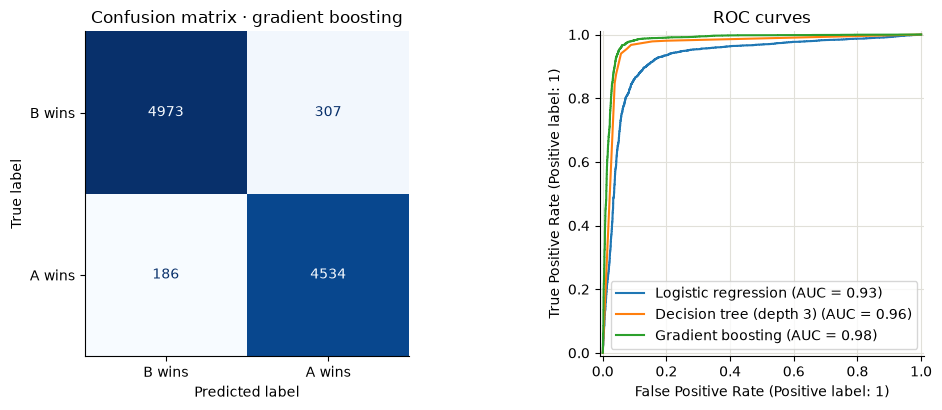

In [22]:
gbm = models["Gradient boosting"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
# 📖 Ch. 3 "Confusion Matrices": rows = actual class, columns = predicted class
ConfusionMatrixDisplay.from_estimator(gbm, X_test, y_test, display_labels=["B wins", "A wins"],
                                      cmap="Blues", colorbar=False, ax=axes[0])
axes[0].set_title("Confusion matrix · gradient boosting"); axes[0].grid(False)
# 📖 Ch. 3 "The ROC Curve": true positive rate vs. false positive rate across all thresholds
for name, m in models.items():
    RocCurveDisplay.from_estimator(m, X_test, y_test, name=name, ax=axes[1])
axes[1].set_title("ROC curves"); plt.tight_layout(); plt.show()

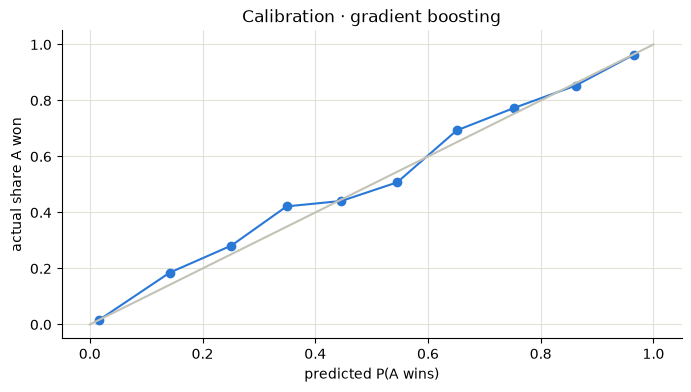

In [23]:
# Calibration: when the model says 80%, does A really win about 80% of the time?
# Probability estimates are discussed in 📖 Ch. 4 "Estimating Probabilities" and Ch. 6 "Estimating Class Probabilities".
prob = gbm.predict_proba(X_test)[:, 1]
bins = pd.cut(prob, np.linspace(0, 1, 11), include_lowest=True)
calib = pd.DataFrame({"predicted": prob, "actual": y_test}).groupby(bins, observed=True).mean()
ax = calib.plot(x="predicted", y="actual", marker="o", color=BLUE, legend=False, title="Calibration · gradient boosting")
ax.plot([0, 1], [0, 1], color=GRAY, label="perfect"); ax.set(xlabel="predicted P(A wins)", ylabel="actual share A won")
plt.show()

### Look at the decision tree

> 📖 **Ch. 6, “Making Predictions”**: a tree is a *white-box* model, so you can read its decisions directly.

The tree's very first question is about Speed: it **rediscovers the simulator's main rule on its own**.

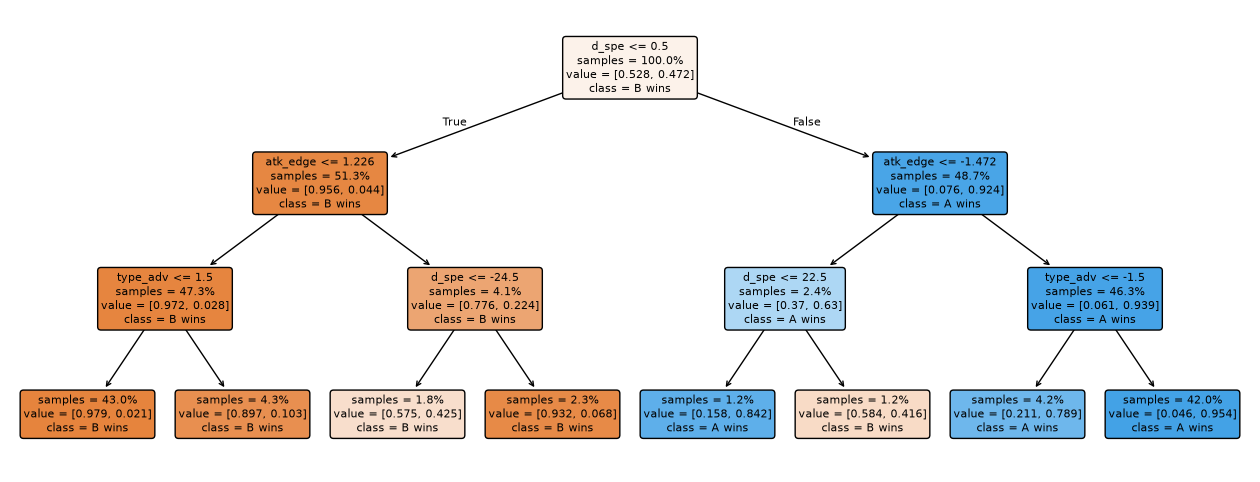

In [24]:
plt.figure(figsize=(16, 6))
plot_tree(models["Decision tree (depth 3)"], feature_names=FEATURES, class_names=["B wins", "A wins"],
          filled=True, rounded=True, impurity=False, proportion=True, fontsize=8)
plt.show()

## 11 · Analyse the model and its errors

> 📖 **Ch. 2, “Analyzing the Best Models and Their Errors”** · **Ch. 7, “Feature Importance”**

The book uses random forests' `feature_importances_`. Here we use **permutation importance**, which works for any model:
shuffle one column and measure how much accuracy drops. Then we check it with an **ablation**: retrain without the feature.

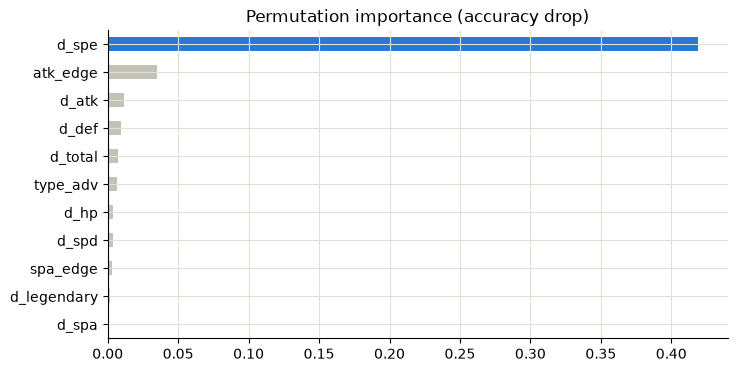

Speed only                 0.9403
Everything except Speed    0.7096
All features               0.9507
dtype: float64

In [25]:
pi = permutation_importance(gbm, X_test, y_test, n_repeats=5, random_state=SEED, scoring="accuracy")
imp = pd.Series(pi.importances_mean, index=FEATURES).sort_values()
ax = imp.plot.barh(color=[BLUE if f == "d_spe" else GRAY for f in imp.index], title="Permutation importance (accuracy drop)")
plt.show()

def gbm_score(cols):
    m = GradientBoostingClassifier(n_estimators=200, max_depth=4, subsample=0.8, random_state=SEED)
    return m.fit(X_train[cols], y_train).score(X_test[cols], y_test)

ablation = pd.Series({
    "Speed only": gbm_score(["d_spe"]),
    "Everything except Speed": gbm_score([f for f in FEATURES if f not in ("d_spe", "d_total")]),
    "All features": gbm.score(X_test, y_test),
})
ablation.round(4)

Speed carries almost everything. **Legendary status adds almost nothing once Speed is known**, which settles the confounding question from Section 5.

### Data leakage: the bug that makes you look brilliant

> 📖 **Ch. 2, “Create a Test Set”** (data snooping) · **Ch. 2, “Transformation Pipelines”** (fit transformations on training data only)

Adding each Pokémon's win rate as a feature is reasonable, **if** it is computed from training battles only. Computed from *all*
battles, it quietly includes the test outcomes.

In [26]:
def win_rate_from(battles):
    g = pd.concat([battles.First_pokemon, battles.Second_pokemon]).value_counts()
    w = battles.Winner.value_counts().reindex(g.index).fillna(0)
    return (w / g).reindex(pokemon.index).fillna(0.5)

def score_with_winrate(wr):
    Xw = X_all.assign(d_wr=wr.loc[combats.First_pokemon].values - wr.loc[combats.Second_pokemon].values)
    m = GradientBoostingClassifier(n_estimators=200, max_depth=4, subsample=0.8, random_state=SEED)
    return m.fit(Xw.iloc[idx_train], y_train).score(Xw.iloc[idx_test], y_test)

print(f"leaky  (win rate from ALL battles):   {score_with_winrate(win_rate_from(combats)):.4f}")
print(f"honest (win rate from train battles): {score_with_winrate(win_rate_from(train_battles)):.4f}")

leaky  (win rate from ALL battles):   0.9517


honest (win rate from train battles): 0.9500


The leak is small here (each Pokémon has about 128 battles, so one test result barely moves its win rate), but with little data per
Pokémon it would be a large, fake improvement. **Nothing computed from the test set may feed a feature.**

A second check: the same matchup can appear in both train and test. Splitting by *matchup* (a group split) tells us whether that inflates the score.

In [27]:
pair = np.minimum(combats.First_pokemon, combats.Second_pokemon) * 1000 + np.maximum(combats.First_pokemon, combats.Second_pokemon)
g_tr, g_te = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED).split(X_all, y_all, groups=pair))
m = GradientBoostingClassifier(n_estimators=200, max_depth=4, subsample=0.8, random_state=SEED).fit(X_all.iloc[g_tr], y_all[g_tr])
print(f"group split by matchup: {m.score(X_all.iloc[g_te], y_all[g_te]):.4f}  (vs {gbm.score(X_test, y_test):.4f} with a random split)")

group split by matchup: 0.9503  (vs 0.9507 with a random split)


### How good could any model be?

> 📖 **Ch. 4, the bias/variance trade-off sidebar**: part of every model's error is *irreducible error*, noise in the data itself.

In [28]:
outcomes = pd.DataFrame({"pair": pair, "winner": combats.Winner}).groupby("pair").winner.agg(["count", "nunique"])
repeats = outcomes[outcomes["count"] > 1]
print(f"{len(repeats):,} matchups happen more than once; {(repeats['nunique'] > 1).sum()} of them had different winners")
print(f"our model's test error: {1 - gbm.score(X_test, y_test):.2%}")

3,573 matchups happen more than once; 110 of them had different winners
our model's test error: 4.93%


## 12 · Present: predict any battle, then the Kaggle submission

> 📖 **Ch. 2 checklist**: present your solution, then launch it.

The same models power the **arena** in the [interactive guide](https://elmandalorian-thx.github.io/PokemonML/#arena).
Here is the notebook version:

In [29]:
name_to_id = {n: i for i, n in pokemon.Name.items()}

def battle(a: str, b: str):
    """Predict a battle between two Pokémon names (A is listed first)."""
    ia, ib = name_to_id[a], name_to_id[b]
    x = pair_features([ia], [ib])
    print(f"{a} (Speed {pokemon.Speed[ia]}) vs {b} (Speed {pokemon.Speed[ib]})")
    for name, m in models.items():
        p = m.predict_proba(x)[0, 1]
        print(f"  {name:25s} P({a} wins) = {p:6.1%}  -> {a if p >= .5 else b}")
    met = combats[((combats.First_pokemon == ia) & (combats.Second_pokemon == ib)) |
                  ((combats.First_pokemon == ib) & (combats.Second_pokemon == ia))]
    print(f"  dataset record: {len(met)} meetings, {a} won {(met.Winner == ia).sum()}" if len(met) else "  never met in the dataset")

battle("Pikachu", "Dragonite")    # speed beats power
print()
battle("Mewtwo", "Jolteon")       # speed tie: the second Pokémon wins...
print()
battle("Jolteon", "Mewtwo")       # ...so swapping the order flips the result

Pikachu (Speed 90) vs Dragonite (Speed 80)
  Logistic regression       P(Pikachu wins) =  37.9%  -> Dragonite
  Decision tree (depth 3)   P(Pikachu wins) =  84.2%  -> Pikachu
  Gradient boosting         P(Pikachu wins) =  94.8%  -> Pikachu
  never met in the dataset

Mewtwo (Speed 130) vs Jolteon (Speed 130)
  Logistic regression       P(Mewtwo wins) =  53.6%  -> Mewtwo
  Decision tree (depth 3)   P(Mewtwo wins) =   2.1%  -> Jolteon
  Gradient boosting         P(Mewtwo wins) =   0.5%  -> Jolteon
  never met in the dataset

Jolteon (Speed 130) vs Mewtwo (Speed 130)
  Logistic regression       P(Jolteon wins) =  34.9%  -> Mewtwo
  Decision tree (depth 3)   P(Jolteon wins) =   2.1%  -> Mewtwo
  Gradient boosting         P(Jolteon wins) =   0.7%  -> Mewtwo
  never met in the dataset


In [30]:
# The Kaggle deliverable: predict the winner of every matchup in tests.csv
X_kaggle = pair_features(tests.First_pokemon.values, tests.Second_pokemon.values)
p_first = gbm.predict_proba(X_kaggle)[:, 1]
submission = tests.assign(Winner=np.where(p_first >= 0.5, tests.First_pokemon, tests.Second_pokemon))

out = Path("../data/output"); out.mkdir(parents=True, exist_ok=True)
submission.to_csv(out / "submission.csv", index=False)
print(f"wrote {len(submission):,} predictions · first Pokémon predicted to win {np.mean(p_first >= .5):.1%}")
submission.head()

wrote 10,000 predictions · first Pokémon predicted to win 48.6%


,First_pokemon,Second_pokemon,Winner
0,129,117,129
1,660,211,211
2,706,115,706
3,195,618,618
4,27,656,27


## Takeaways

1. **Frame it first**: inputs, target, metric and a test set before any modelling (📖 Ch. 2).
2. **Understand every column**: a blank `Type 2` isn't missing data (📖 Ch. 2 *Clean the Data*).
3. **Split before you explore** to avoid data snooping (📖 Ch. 2 *Create a Test Set*).
4. **Beat a baseline**: a one-line rule scored about 94% (📖 Ch. 3).
5. **Fit the model to the shape of the problem**: steps need trees, or a step feature (📖 Ch. 4, Ch. 6).
6. **Test your assumptions**: augmentation that breaks a real rule hurts (📖 Ch. 3 exercises).
7. **Watch the train/validation gap**: deeper isn't better (📖 Ch. 1, Ch. 6).
8. **Guard against leakage**: nothing from the test set may touch the features (📖 Ch. 2).

## Exercises

1. Add *is faster* and *speed tie* flags to the boosting model, then tune `HistGradientBoostingClassifier`
   (📖 Ch. 7 *Histogram-Based Gradient Boosting*) with `GridSearchCV` (📖 Ch. 2 *Grid Search*). Can you beat 95%?
2. Try a random forest (📖 Ch. 7 *Random Forests*) and compare its `feature_importances_` with the permutation importance above.
3. Train on Generations 1–5 and test on Generation 6. Does the model generalise to Pokémon it has never seen? (📖 Ch. 1 *Data Mismatch*)
4. Write a tiny battle simulator by hand (faster attacks first, damage ∝ Attack ÷ Defense). Can hand-written rules match the learned ones?
5. Diego Rosa's article (see *Related reading*) builds features from the game's damage formula, such as *proportional damage* and
   *damage ÷ opponent HP*. Add them to `pair_features` and compare the cross-validation score. Do they add anything beyond our edge features?

---

### Credits

* **Notebook, analysis and interactive guide:** [Juan Barahona](https://github.com/elmandalorian-thx) · https://github.com/elmandalorian-thx/PokemonML
* **Data:** [Pokemon – Weedle's Cave](https://www.kaggle.com/datasets/terminus7/pokemon-challenge) by T7 – Hackathon Challenge (terminus7), published on **Kaggle** under CC0: Public Domain. Thank you for the dataset and the challenge.
* **Book:** Aurélien Géron, *Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow*, 3rd ed. (O'Reilly, 2022), ISBN 978-1-098-12597-4.
  The 📖 references point to its chapters; all explanations here are our own summaries.
* **Related reading:** Diego Rosa, [“Your favorite game from a different point of view”](https://towardsdatascience.com/your-favorite-game-from-a-different-point-of-view-93732173adf7/),
  *Towards Data Science*, August 2020: an exploratory analysis of the same Kaggle dataset, with damage-formula features and a data-driven Gen-1 team.
* Pokémon and all related names are trademarks of Nintendo, Game Freak and The Pokémon Company. This is an educational, non-commercial project.